In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
from sklearn.inspection import DecisionBoundaryDisplay

sns.set_theme(style="whitegrid")

## 1. Load and Explore the Dataset

In [2]:

iris = load_iris()
df = pd.DataFrame(data=iris.data, columns=iris.feature_names)
df['target'] = iris.target
df['species'] = df['target'].map({i: name for i, name in enumerate(iris.target_names)})

print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (150, 6)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


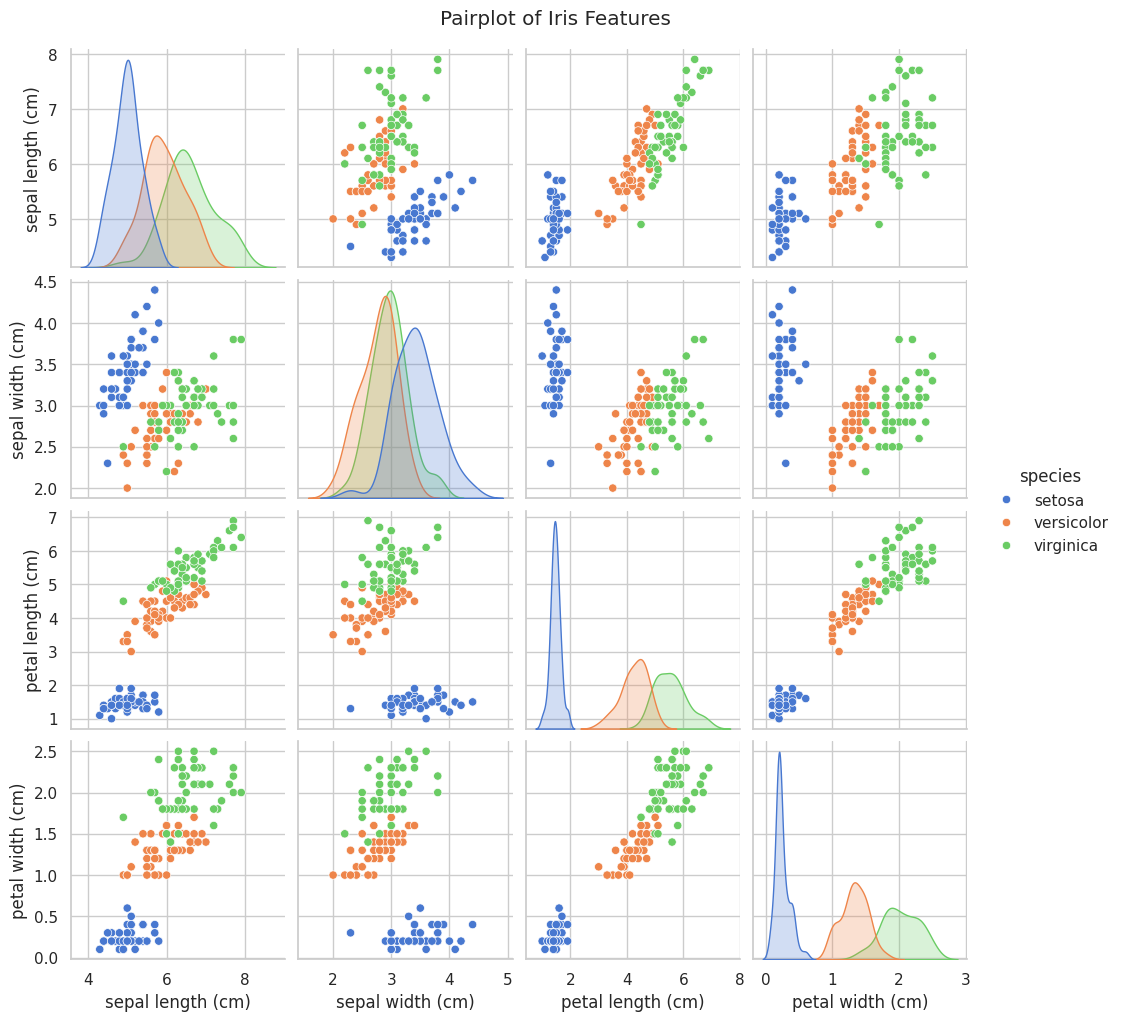

In [3]:

sns.pairplot(df.drop(columns=['target']), hue='species', palette='muted')
plt.suptitle("Pairplot of Iris Features", y=1.02)
plt.show()

## 2. Preprocess, Scale, and Split Data

In [4]:

X = df[iris.feature_names]
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Training set shape: {X_train_scaled.shape}")
print(f"Testing set shape: {X_test_scaled.shape}")

Training set shape: (120, 4)
Testing set shape: (30, 4)


## 3. Train and Evaluate Models

In [5]:

models = {
    "Logistic Regression": LogisticRegression(random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42)
}

results = {}

for name, model in models.items():

    model.fit(X_train_scaled, y_train)

    y_pred = model.predict(X_test_scaled)


    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, average='weighted')
    rec = recall_score(y_test, y_pred, average='weighted')
    f1 = f1_score(y_test, y_pred, average='weighted')

    results[name] = {
        "Accuracy": acc,
        "Precision (Weighted)": prec,
        "Recall (Weighted)": rec,
        "F1-Score (Weighted)": f1,
        "Predictions": y_pred,
        "Model": model
    }

    print(f"=== {name} Classification Report ===")
    print(classification_report(y_test, y_pred, target_names=iris.target_names))
    print("\n")

=== Logistic Regression Classification Report ===
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



=== Decision Tree Classification Report ===
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30





## 4. Plot Confusion Matrices

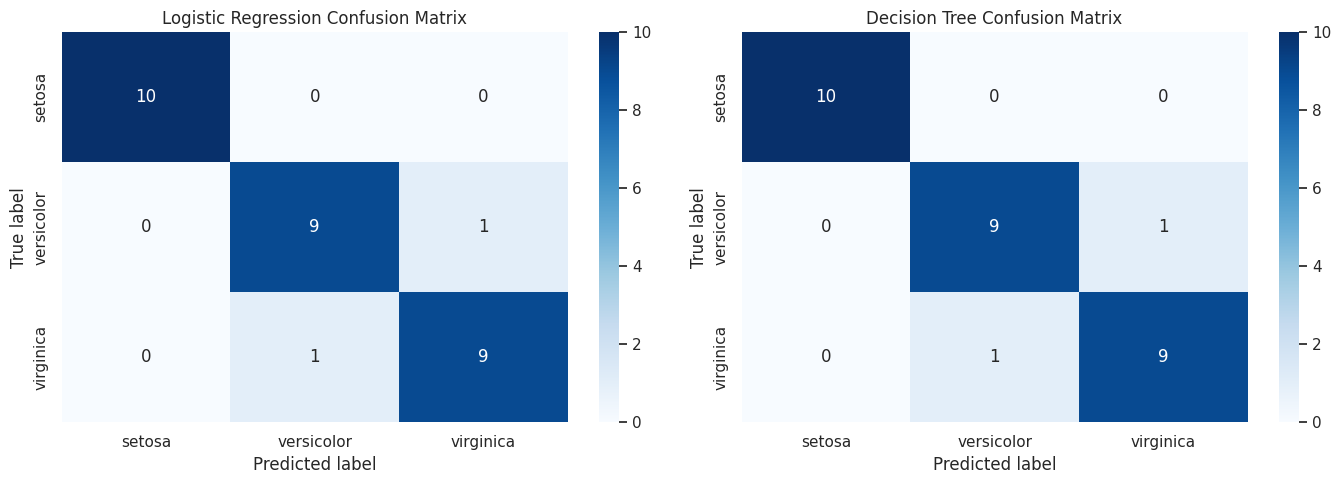

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for i, (name, res) in enumerate(results.items()):
    cm = confusion_matrix(y_test, res["Predictions"])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i],
                xticklabels=iris.target_names, yticklabels=iris.target_names)
    axes[i].set_title(f"{name} Confusion Matrix")
    axes[i].set_xlabel("Predicted label")
    axes[i].set_ylabel("True label")

plt.tight_layout()
plt.show()

## 5. Decision Boundary Visualization

To visualize decision boundaries in 2D, we will train new instances of both models using only the first two features (Sepal Length and Sepal Width).

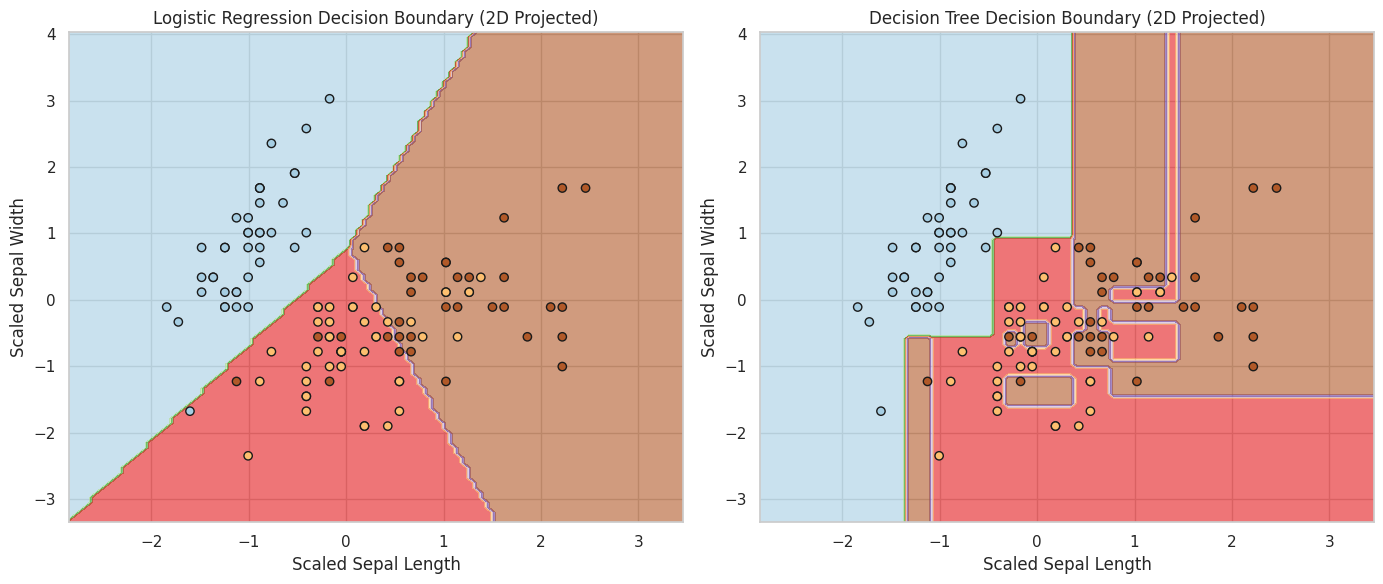

In [7]:

X_2d = X.iloc[:, :2]

X_train_2d, X_test_2d, y_train_2d, y_test_2d = train_test_split(X_2d, y, test_size=0.20, random_state=42, stratify=y)
scaler_2d = StandardScaler()
X_train_2d_scaled = scaler_2d.fit_transform(X_train_2d)

lr_2d = LogisticRegression(random_state=42).fit(X_train_2d_scaled, y_train_2d)
dt_2d = DecisionTreeClassifier(random_state=42).fit(X_train_2d_scaled, y_train_2d)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

models_2d = {"Logistic Regression": lr_2d, "Decision Tree": dt_2d}

for i, (name, clf) in enumerate(models_2d.items()):
    DecisionBoundaryDisplay.from_estimator(
        clf,
        X_train_2d_scaled,
        response_method="predict",
        cmap=plt.cm.Paired,
        ax=axes[i],
        alpha=0.6,
    )

    scatter = axes[i].scatter(
        X_train_2d_scaled[:, 0],
        X_train_2d_scaled[:, 1],
        c=y_train_2d,
        edgecolors="k",
        cmap=plt.cm.Paired
    )
    axes[i].set_title(f"{name} Decision Boundary (2D Projected)")
    axes[i].set_xlabel("Scaled Sepal Length")
    axes[i].set_ylabel("Scaled Sepal Width")

plt.tight_layout()
plt.show()

In [8]:
from google.colab import files
# Note: This programmatically saves and downloads the current notebook in Google Colab.
import json
from google.colab import userdata

try:
    # Attempting to save the state and download
    import ipykernel
    print("To download your current notebook directly, go to File -> Download -> Download .ipynb in the top-left menu.")
except Exception as e:
    pass

To download your current notebook directly, go to File -> Download -> Download .ipynb in the top-left menu.
